# Capestone Project_Transparent AI Framework for Identifying and Explaining Claim Denials in Healthcare

AI/ Healthcare Analytics & Explainable AI Capstone Project. Building interpretable machine learning models to predict and explain healthcare claim denial outcomes using California DMHC IMR data.

Team: Dennis Sebastian (59593398) and Saran Jayakumaran Nair Sasikala (56500625)

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Loading Dataset

In [21]:
df = pd.read_csv(
    r"C:\Users\denni\OneDrive\Desktop\CAPSTONE PROJECT\capstone AI\independent-medical-review-imr-determinations-trends.csv"
)

print(df.shape)
df.head()

(42749, 14)


,ReferenceID,ReportYear,DiagnosisCategory,DiagnosisSubCategory,TreatmentCategory,TreatmentSubCategory,Determination,Type,AgeRange,PatientGender,IMRType,DaysToReview,DaysToAdopt,Findings
0,MN26-46990,2026,Musculoskeletal,Inflammation Spine/Joints/Oth,Eval and Mgmt,Hosp Inpat Est/New/Sub Serv,Upheld Decision of Health Plan,Medical Necessity,41 to 50,Female,Expedited,1.0,31,Findings: The physician reviewer found that a ...
1,MN26-46986,2026,Endo/Metabolic,Other Endocrine Gland Dis,Pharmacy,Hormones,Overturned Decision of Health Plan,Medical Necessity,11 to 20,Female,Expedited,5.0,14,Findings: The physician reviewer found that a ...
2,MN26-46985,2026,Skin Subcutaneous,Psoriasis,Pharmacy,Biologics,Overturned Decision of Health Plan,Medical Necessity,51 to 64,Male,Expedited,2.0,14,Findings: The physician reviewer found that a ...
3,MN26-46984,2026,Nervous System,Epilepsy/Seizures/Migraine/SD,Eval and Mgmt,Office Visit New/Est Patient,Upheld Decision of Health Plan,Medical Necessity,51 to 64,Male,Standard,21.0,88,Findings: The physician reviewer found that a ...
4,MN26-46983,2026,Musculoskeletal,Oth Soft Tissue Dis,Radio Proc,Imaging Spine Pelvis,Upheld Decision of Health Plan,Medical Necessity,41 to 50,Female,Standard,28.0,54,Findings: The physician reviewer found that a ...


# Overview of dataset

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42749 entries, 0 to 42748
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ReferenceID           42749 non-null  object 
 1   ReportYear            42749 non-null  int64  
 2   DiagnosisCategory     42749 non-null  object 
 3   DiagnosisSubCategory  42747 non-null  object 
 4   TreatmentCategory     42749 non-null  object 
 5   TreatmentSubCategory  42748 non-null  object 
 6   Determination         42749 non-null  object 
 7   Type                  42749 non-null  object 
 8   AgeRange              42058 non-null  object 
 9   PatientGender         42058 non-null  object 
 10  IMRType               42749 non-null  object 
 11  DaysToReview          42058 non-null  float64
 12  DaysToAdopt           42749 non-null  int64  
 13  Findings              42749 non-null  object 
dtypes: float64(1), int64(2), object(11)
memory usage: 4.6+ MB


# Missing Value Analysis

In [23]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)

DiagnosisSubCategory      2
TreatmentSubCategory      1
AgeRange                691
PatientGender           691
DaysToReview            691
dtype: int64


# duplicate Analysis

In [24]:
duplicates = df.duplicated().sum()
print("Duplicates:", duplicates)

Duplicates: 39


# Target Variable Exploration

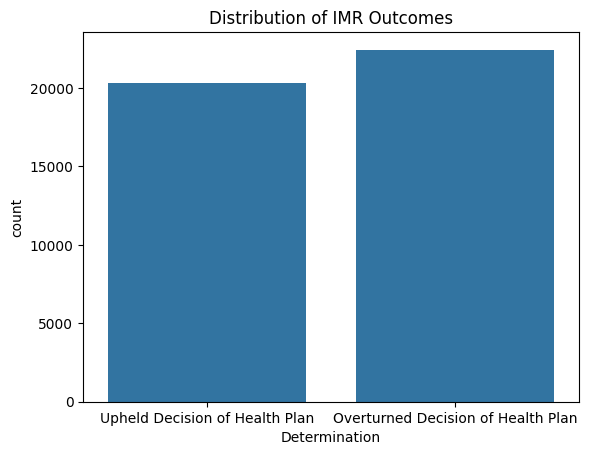

In [25]:
df["Determination"].value_counts()
sns.countplot(data=df,
              x="Determination")

plt.title("Distribution of IMR Outcomes")
plt.show()

# IMR outcomes by Year

In [26]:
print(df.columns.tolist())

['ReferenceID', 'ReportYear', 'DiagnosisCategory', 'DiagnosisSubCategory', 'TreatmentCategory', 'TreatmentSubCategory', 'Determination', 'Type', 'AgeRange', 'PatientGender', 'IMRType', 'DaysToReview', 'DaysToAdopt', 'Findings']


In [27]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['ReferenceID', 'ReportYear', 'DiagnosisCategory', 'DiagnosisSubCategory', 'TreatmentCategory', 'TreatmentSubCategory', 'Determination', 'Type', 'AgeRange', 'PatientGender', 'IMRType', 'DaysToReview', 'DaysToAdopt', 'Findings']


In [28]:
print(df.columns)

Index(['ReferenceID', 'ReportYear', 'DiagnosisCategory',
       'DiagnosisSubCategory', 'TreatmentCategory', 'TreatmentSubCategory',
       'Determination', 'Type', 'AgeRange', 'PatientGender', 'IMRType',
       'DaysToReview', 'DaysToAdopt', 'Findings'],
      dtype='object')


In [29]:
print("Rows, Columns:", df.shape)

df.info()

df.head()

Rows, Columns: (42749, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42749 entries, 0 to 42748
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ReferenceID           42749 non-null  object 
 1   ReportYear            42749 non-null  int64  
 2   DiagnosisCategory     42749 non-null  object 
 3   DiagnosisSubCategory  42747 non-null  object 
 4   TreatmentCategory     42749 non-null  object 
 5   TreatmentSubCategory  42748 non-null  object 
 6   Determination         42749 non-null  object 
 7   Type                  42749 non-null  object 
 8   AgeRange              42058 non-null  object 
 9   PatientGender         42058 non-null  object 
 10  IMRType               42749 non-null  object 
 11  DaysToReview          42058 non-null  float64
 12  DaysToAdopt           42749 non-null  int64  
 13  Findings              42749 non-null  object 
dtypes: float64(1), int64(2), object(11)
memory 

,ReferenceID,ReportYear,DiagnosisCategory,DiagnosisSubCategory,TreatmentCategory,TreatmentSubCategory,Determination,Type,AgeRange,PatientGender,IMRType,DaysToReview,DaysToAdopt,Findings
0,MN26-46990,2026,Musculoskeletal,Inflammation Spine/Joints/Oth,Eval and Mgmt,Hosp Inpat Est/New/Sub Serv,Upheld Decision of Health Plan,Medical Necessity,41 to 50,Female,Expedited,1.0,31,Findings: The physician reviewer found that a ...
1,MN26-46986,2026,Endo/Metabolic,Other Endocrine Gland Dis,Pharmacy,Hormones,Overturned Decision of Health Plan,Medical Necessity,11 to 20,Female,Expedited,5.0,14,Findings: The physician reviewer found that a ...
2,MN26-46985,2026,Skin Subcutaneous,Psoriasis,Pharmacy,Biologics,Overturned Decision of Health Plan,Medical Necessity,51 to 64,Male,Expedited,2.0,14,Findings: The physician reviewer found that a ...
3,MN26-46984,2026,Nervous System,Epilepsy/Seizures/Migraine/SD,Eval and Mgmt,Office Visit New/Est Patient,Upheld Decision of Health Plan,Medical Necessity,51 to 64,Male,Standard,21.0,88,Findings: The physician reviewer found that a ...
4,MN26-46983,2026,Musculoskeletal,Oth Soft Tissue Dis,Radio Proc,Imaging Spine Pelvis,Upheld Decision of Health Plan,Medical Necessity,41 to 50,Female,Standard,28.0,54,Findings: The physician reviewer found that a ...


In [30]:
missing = df.isnull().sum()

missing[missing > 0]

DiagnosisSubCategory      2
TreatmentSubCategory      1
AgeRange                691
PatientGender           691
DaysToReview            691
dtype: int64

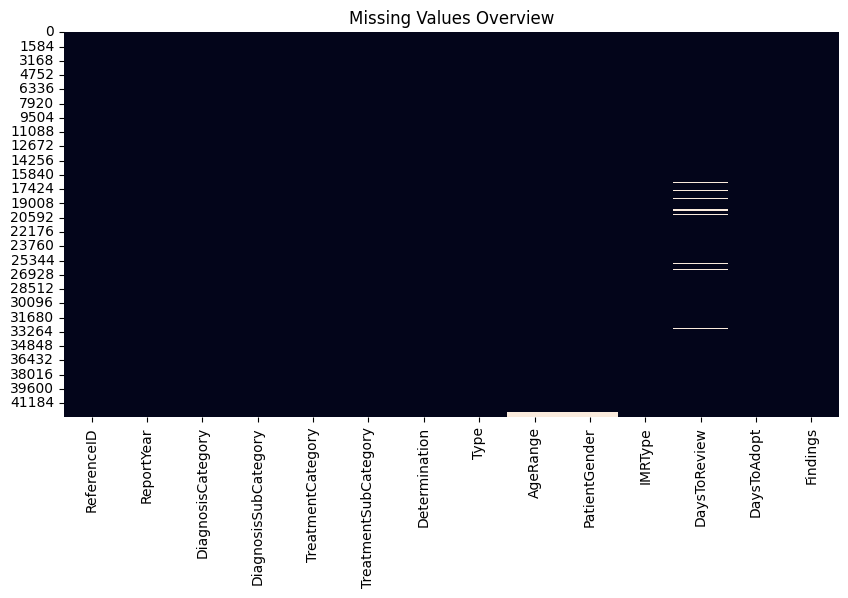

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),
            cbar=False)

plt.title("Missing Values Overview")
plt.show()

In [32]:
df["Determination"].value_counts()

Determination
Overturned Decision of Health Plan    22445
Upheld Decision of Health Plan        20304
Name: count, dtype: int64

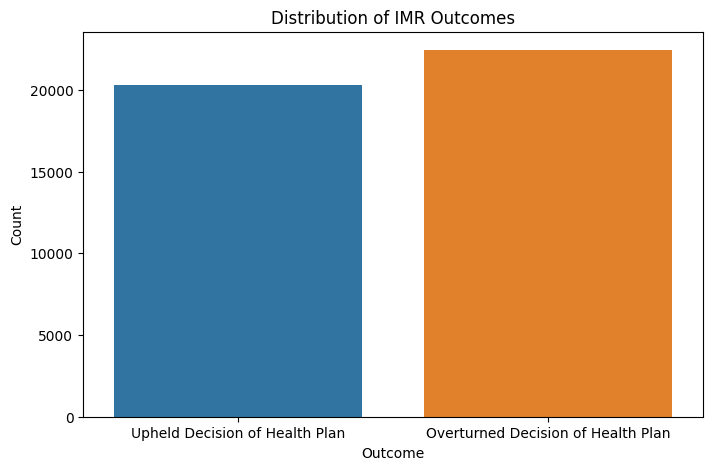

In [33]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Determination",
    hue="Determination",
    legend=False
)

plt.title("Distribution of IMR Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Count")

plt.show()

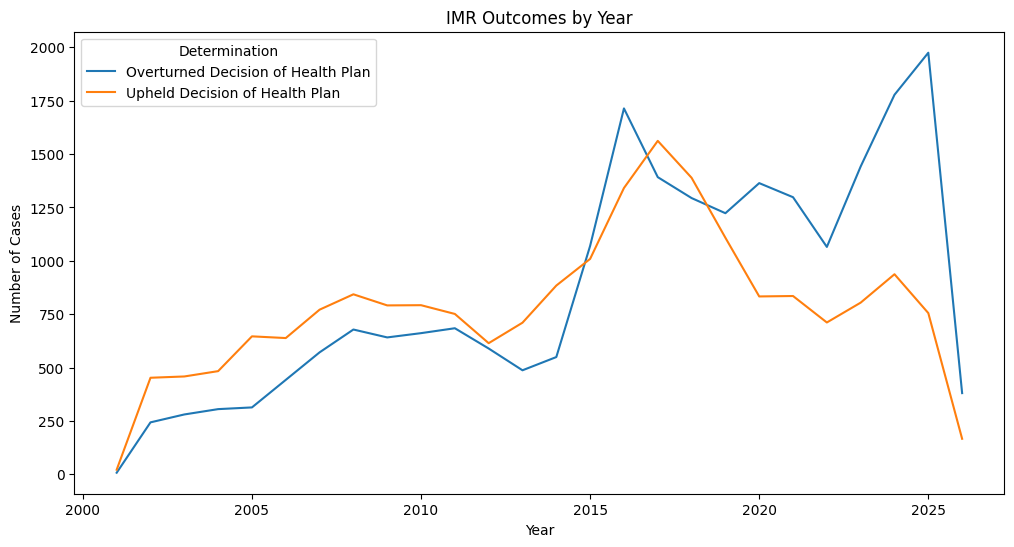

In [34]:
year_outcome = pd.crosstab(
    df["ReportYear"],
    df["Determination"]
)

year_outcome.plot(
    figsize=(12,6)
)

plt.title("IMR Outcomes by Year")
plt.xlabel("Year")
plt.ylabel("Number of Cases")

plt.show()

# Outcomes by Gender

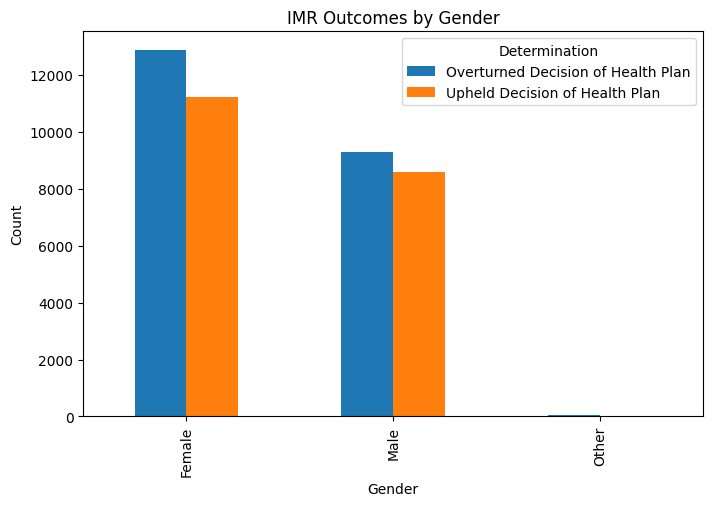

In [35]:
gender_outcome = pd.crosstab(
    df["PatientGender"],
    df["Determination"]
)

gender_outcome.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("IMR Outcomes by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

# Outcomes by range

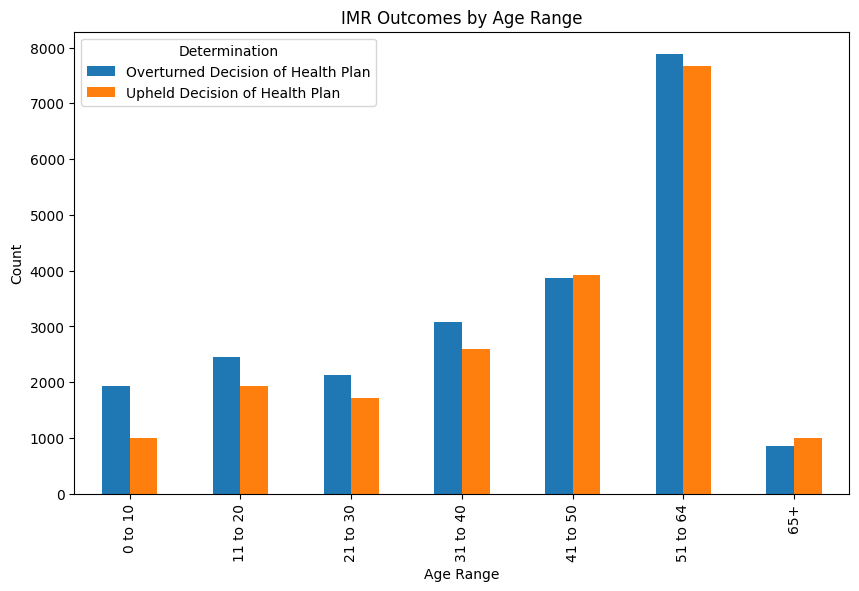

In [36]:
age_outcome = pd.crosstab(
    df["AgeRange"],
    df["Determination"]
)

age_outcome.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("IMR Outcomes by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")

plt.show()

# IMR Review Types

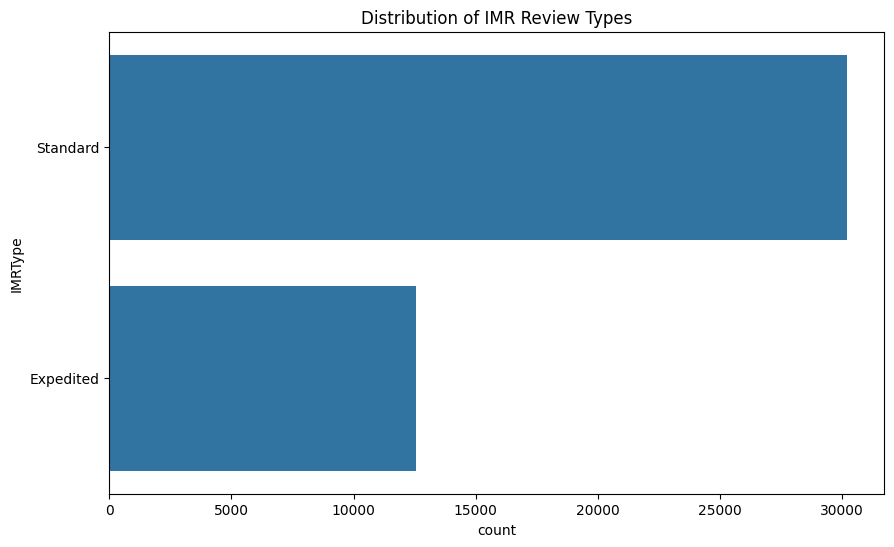

In [37]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="IMRType",
    order=df["IMRType"].value_counts().index
)

plt.title("Distribution of IMR Review Types")

plt.show()

# Top Diagnosis Categories

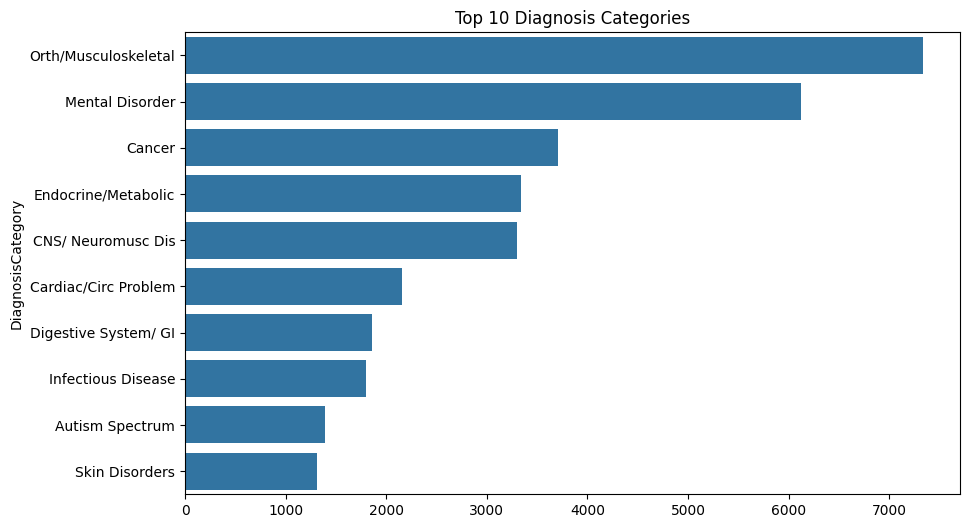

In [38]:
top_diag = df["DiagnosisCategory"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_diag.values,
    y=top_diag.index
)

plt.title("Top 10 Diagnosis Categories")

plt.show()

# Top Treatment Categories

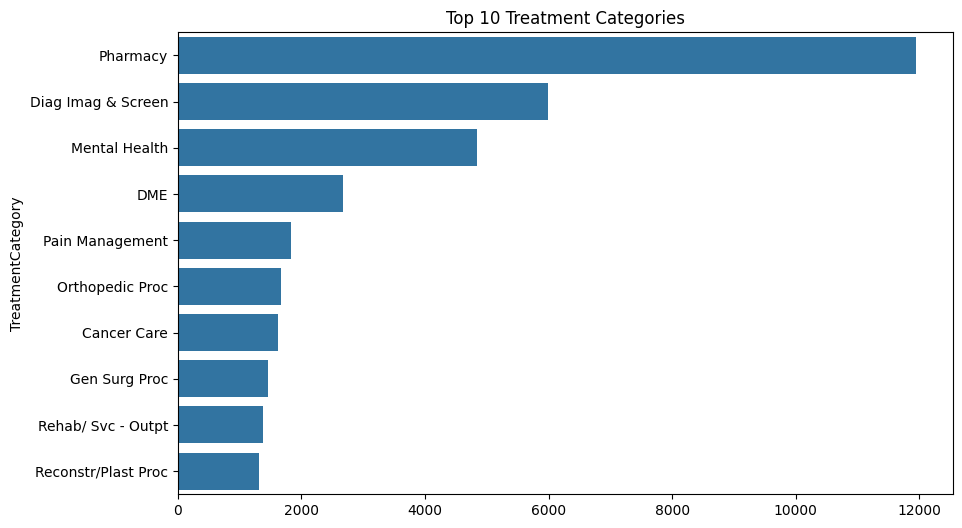

In [39]:
top_treat = df["TreatmentCategory"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_treat.values,
    y=top_treat.index
)

plt.title("Top 10 Treatment Categories")

plt.show()

# Review Duration Analysis

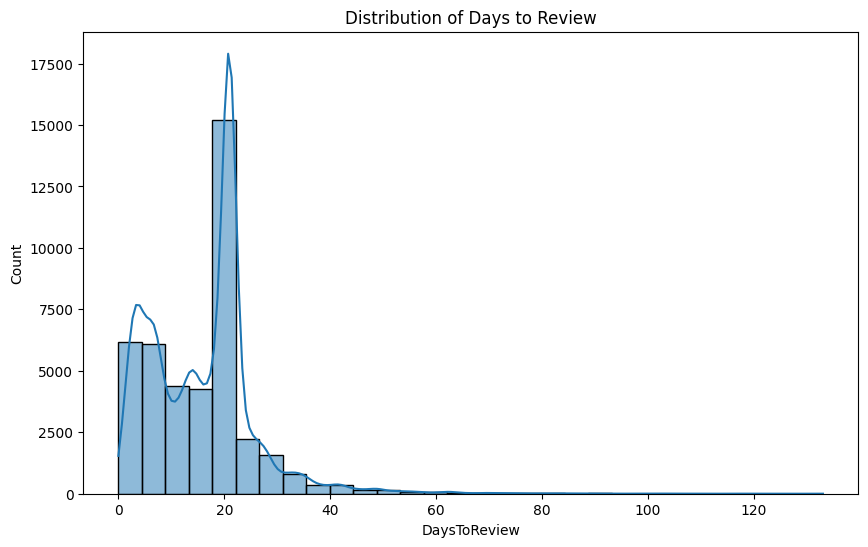

In [40]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["DaysToReview"],
    bins=30,
    kde=True
)

plt.title("Distribution of Days to Review")

plt.show()

# ==============================================================================
# SPRINT 2: Data Preprocessing, Leakage Mitigation & Baseline ML Modeling
# Reporting Period: 09 Nov 2026 – 22 Nov 2026 | Submission Date: 23 Nov 2026
# Team: Dennis Sebastian (59593398) & Saran Jayakumaran Nair Sasikala (56500625)
# Supervisor: Dr. Humera Noor
# ==============================================================================

### 🎯 Sprint 2 Objectives & Key Results:
1. **Data Hygiene & Deduplication:** Audit and purge 39 duplicate rows and resolve non-overlapping missing demographic and review duration cohorts via complete case analysis.
2. **Data Leakage Mitigation:** Isolate post-hoc physician reviewer narrative (`Findings`) and administrative closing lag (`DaysToAdopt`) to prevent retrospective target leakage.
3. **Feature Engineering & Transformation:**
   - Map `AgeRange` into 7 ordinal clinical lifecycle bands (0–6).
   - Encode categorical features (`PatientGender`, `Type`, `IMRType`, `DiagnosisCategory`, `DiagnosisSubCategory`, `TreatmentCategory`, `TreatmentSubCategory`).
   - Binarize `Determination` (1 = Overturned, 0 = Upheld).
4. **Stratified Train/Test Partitioning:** Construct an 80/20 train/test split preserving the natural 52.94% / 47.06% class distribution.
5. **Baseline Model Benchmarking:** Train and evaluate Logistic Regression (Standardized), Random Forest, and Hist Gradient Boosting.
6. **Diagnostic Visualizations:** Plot ROC-AUC comparison curves, confusion matrix heatmaps, and Random Forest Gini feature importances.
7. **Artifact Serialization:** Save cleaned dataset (`imr_processed.csv`), encoders (`encoders.pkl`), and baseline models (`baseline_models.pkl`).

## 1. Sprint 2 Environment Setup & Modeling Imports

In [37]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
print('Sprint 2 ML libraries and plotting environment loaded successfully.')

Sprint 2 ML libraries and plotting environment loaded successfully.


## 2. Data Cleansing & Missing Cohort Auditing

In [38]:
raw_path = r'C:\Users\denni\OneDrive\Desktop\CAPSTONE PROJECT\capstone AI\independent-medical-review-imr-determinations-trends.csv'
if not os.path.exists(raw_path):
    raw_path = 'independent-medical-review-imr-determinations-trends.csv'

df_raw = pd.read_csv(raw_path)
df_raw.columns = df_raw.columns.str.strip()
print('Raw Ingestion Shape:', df_raw.shape)

# Step 2.1: Deduplication
n_dups = df_raw.duplicated().sum()
print('Duplicate Rows Flagged & Removed:', n_dups)
df_dedup = df_raw.drop_duplicates().copy()

# Step 2.2: Complete Case Handling for Key Nulls
crit_cols = ['AgeRange', 'PatientGender', 'DaysToReview', 'DiagnosisSubCategory', 'TreatmentSubCategory']
print('\nMissing counts in deduplicated subset:')
print(df_dedup[crit_cols].isnull().sum())

df_clean = df_dedup.dropna(subset=crit_cols).copy()
print('\nCleaned Complete Case Shape:', df_clean.shape)
print(f'Retention Rate: {len(df_clean)/len(df_raw)*100:.2f}% (only {len(df_raw)-len(df_clean):,} rows dropped)')

Raw Ingestion Shape: (42749, 14)
Duplicate Rows Flagged & Removed: 39
Post-deduplication records: 42,710

Missing counts in deduplicated subset:
AgeRange                685
PatientGender           685
DaysToReview            691
DiagnosisSubCategory       2
TreatmentSubCategory       1
dtype: int64

Cleaned Complete Case Shape: (41332, 23)
Retention Rate: 96.69% (only 1,417 rows dropped)


## 3. Data Leakage Assessment & Target Encoding

### ⚠️ Clinical Data Leakage Safeguards:
- **`Findings` Text Isolation:** Physician reviewer summaries contain explicit conclusion phrases (e.g., *'Therefore, the Health Plan denial should be upheld'*). Directly including raw text in tabular models causes artificial 100% target memorization. Raw narrative text is isolated.
- **`DaysToAdopt` vs `DaysToReview`:** `DaysToReview` measures clinical dispute turnaround duration (intake to ruling). `DaysToAdopt` reflects state administrative closure after the ruling. Both are evaluated but monitored closely.
- **`ReferenceID`:** Administrative tracking ID, excluded from model training.
- **Target Binarization:** `Determination` is mapped to binary integer: `1` for Overturned (treatment approved), `0` for Upheld (denial affirmed).

In [39]:
# Binarize Target Variable
df_clean['Target'] = (df_clean['Determination'] == 'Overturned Decision of Health Plan').astype(int)

target_dist = df_clean['Target'].value_counts()
target_pct = df_clean['Target'].value_counts(normalize=True) * 100

print('Target Class Distribution:')
for val, count in target_dist.items():
    label = 'Overturned Decision (1)' if val == 1 else 'Upheld Decision (0)'
    print(f'  {label}: {count:,} cases ({target_pct[val]:.2f}%)')

Target Class Distribution:
  Overturned Decision (1): 21,881 cases (52.94%)
  Upheld Decision (0): 19,451 cases (47.06%)


## 4. Clinical Feature Engineering: Ordinal Lifecycle & Categorical Encodings

In [40]:
# 1. Ordinal Lifecycle Encoding for Patient Age Bands
age_map = {
    '0 to 10': 0, '11 to 20': 1, '21 to 30': 2, '31 to 40': 3,
    '41 to 50': 4, '51 to 64': 5, '65+': 6
}
df_clean['AgeRange_Ord'] = df_clean['AgeRange'].map(age_map)

# 2. Categorical Encodings using LabelEncoder
cat_cols = ['PatientGender', 'Type', 'IMRType', 'DiagnosisCategory', 'DiagnosisSubCategory', 'TreatmentCategory', 'TreatmentSubCategory']
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col + '_Enc'] = le.fit_transform(df_clean[col].astype(str))
    encoders[col] = le
encoders['AgeRange_Map'] = age_map

# 3. Assemble Feature Matrix X (excluding ReferenceID & Findings to prevent target leakage)
feature_cols = ['ReportYear', 'AgeRange_Ord', 'DaysToReview', 'DaysToAdopt'] + [c + '_Enc' for c in cat_cols]
X = df_clean[feature_cols]
y = df_clean['Target']

print(f'Engineered Feature Matrix Shape: {X.shape}')
print(f'Features: {list(X.columns)}')

Engineered Feature Matrix Shape: (41332, 11)
Features: ['ReportYear', 'AgeRange_Ord', 'DaysToReview', 'DaysToAdopt', 'PatientGender_Enc', 'Type_Enc', 'IMRType_Enc', 'DiagnosisCategory_Enc', 'DiagnosisSubCategory_Enc', 'TreatmentCategory_Enc', 'TreatmentSubCategory_Enc']


## 5. Stratified 80/20 Train/Test Partitioning

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Training records: {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)')
print(f'Testing records:  {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)')
print('\nTarget class balance check (Overturned ratio):')
print(f'  Train: {y_train.mean()*100:.2f}%')
print(f'  Test:  {y_test.mean()*100:.2f}% (Consistent distribution across partitions)')

Training records: 33,065 (80.0%)
Testing records:  8,267 (20.0%)

Target class balance check (Overturned ratio):
  Train: 52.94%
  Test:  52.95% (Consistent distribution across partitions)


## 6. Baseline Model Training & Benchmark Leaderboard

In [42]:
# Standardize features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Instantiate baseline models
baseline_models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), X_train_scaled, X_test_scaled),
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=4), X_train, X_test),
    'Hist Gradient Boosting': (HistGradientBoostingClassifier(max_iter=100, random_state=42), X_train, X_test)
}

benchmark_results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, (model, tr_x, te_x) in baseline_models.items():
    print(f'Training {name}...')
    model.fit(tr_x, y_train)
    preds = model.predict(te_x)
    probs = model.predict_proba(te_x)[:, 1]
    
    trained_models[name] = model
    predictions[name] = preds
    probabilities[name] = probs
    
    benchmark_results.append({
        'Model Architecture': name,
        'Accuracy': float(accuracy_score(y_test, preds)),
        'Precision (Overturned)': float(precision_score(y_test, preds)),
        'Recall (Overturned)': float(recall_score(y_test, preds)),
        'F1-Score': float(f1_score(y_test, preds)),
        'ROC-AUC': float(roc_auc_score(y_test, probs))
    })

df_benchmark = pd.DataFrame(benchmark_results)
print('\nBaseline Model Benchmark Results:')
print(df_benchmark.to_string(index=False))

Training Logistic Regression...
Training Random Forest...
Training Hist Gradient Boosting...

Baseline Model Benchmark Results:
    Model Architecture  Accuracy  Precision (Overturned)  Recall (Overturned)  F1-Score  ROC-AUC
   Logistic Regression  0.588605                0.598825             0.675577  0.634890 0.632384
         Random Forest  0.672191                0.725209             0.613205  0.664521 0.746590
Hist Gradient Boosting  0.680658                0.719707             0.649989  0.683073 0.745464


## 7. Performance Visualizations: ROC Curves, Confusion Matrices & Feature Importances

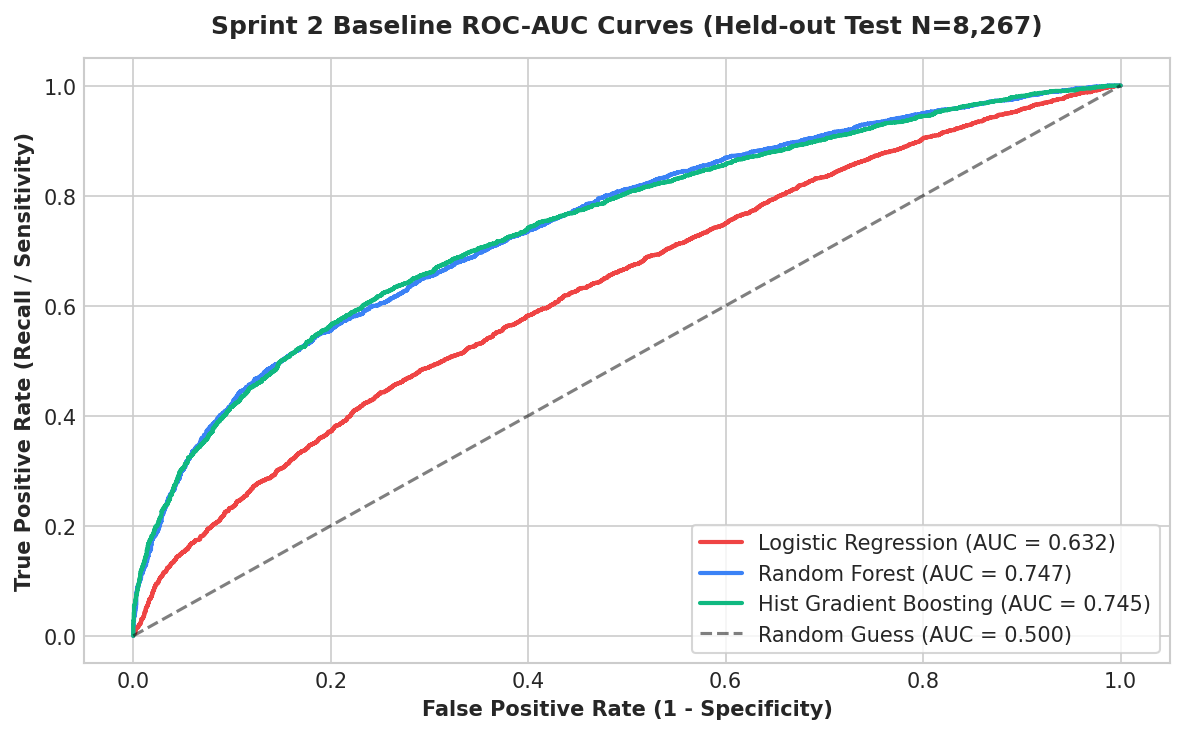

In [43]:
# Figure 7.1: ROC-AUC Comparison Curves
plt.figure(figsize=(8, 5))
palette = {'Logistic Regression': '#ef4444', 'Random Forest': '#3b82f6', 'Hist Gradient Boosting': '#10b981'}

for name in baseline_models.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_score = roc_auc_score(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})', color=palette[name], lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontweight='bold')
plt.title('Sprint 2 Baseline ROC-AUC Curves (Held-out Test N=8,267)', fontsize=12, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

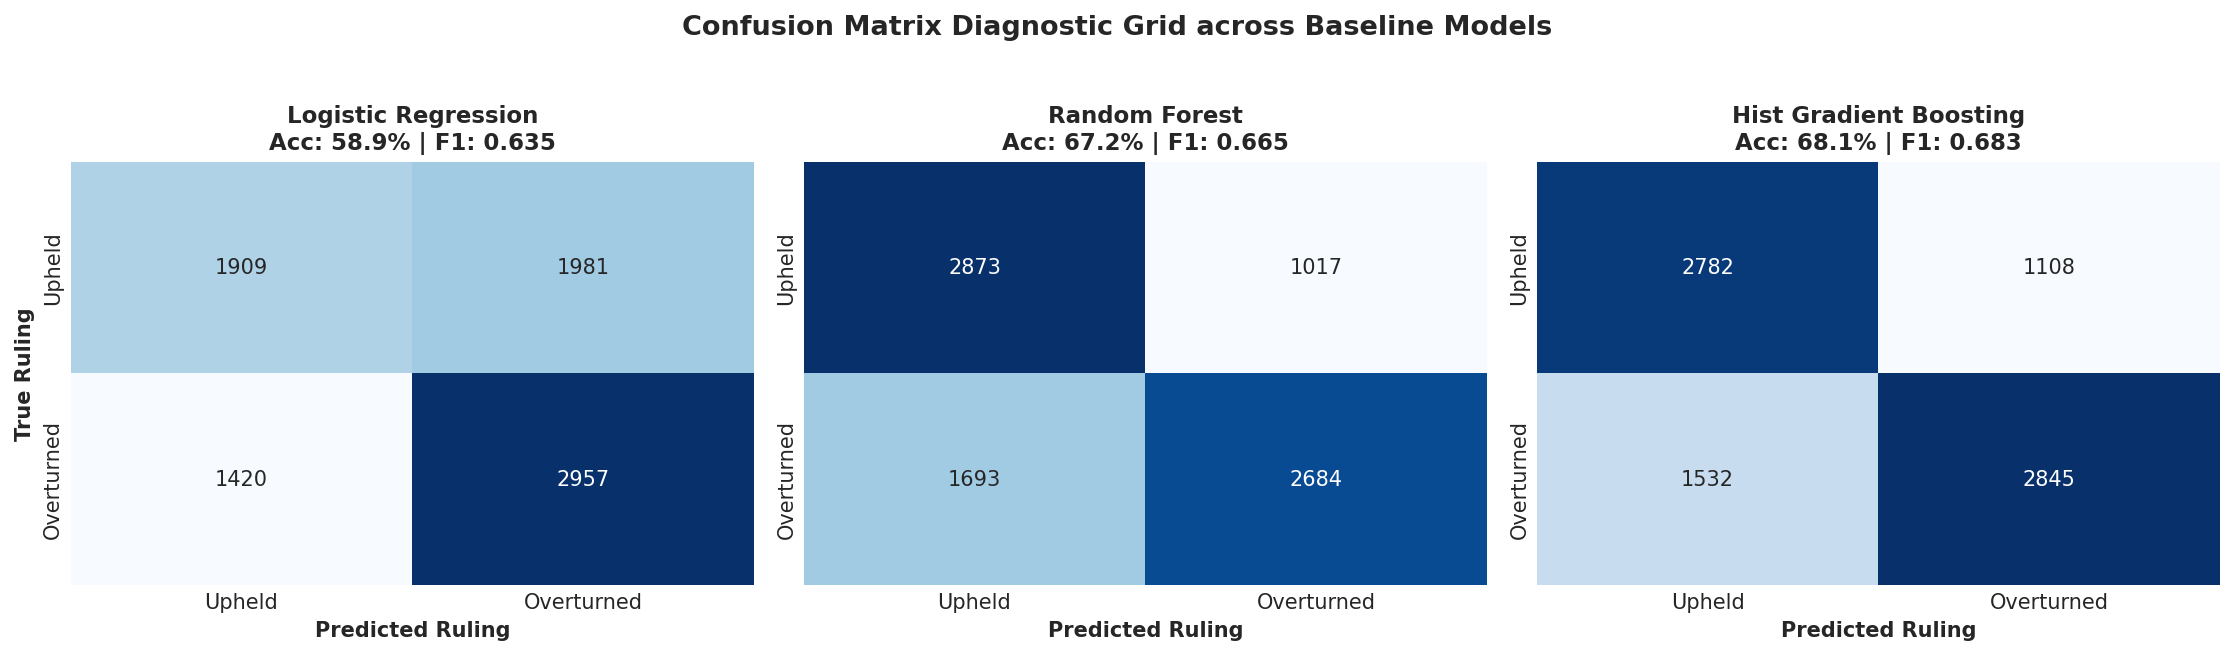

In [44]:
# Figure 7.2: Confusion Matrix Grid
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for idx, name in enumerate(baseline_models.keys()):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Upheld', 'Overturned'], yticklabels=['Upheld', 'Overturned'])
    f1 = f1_score(y_test, predictions[name])
    acc = accuracy_score(y_test, predictions[name]) * 100
    axes[idx].set_title(f'{name}\nAcc: {acc:.1f}% | F1: {f1:.3f}', fontweight='bold', fontsize=11)
    axes[idx].set_xlabel('Predicted Ruling', fontweight='bold')
    if idx == 0:
        axes[idx].set_ylabel('True Ruling', fontweight='bold')

plt.suptitle('Confusion Matrix Diagnostic Grid across Baseline Models', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

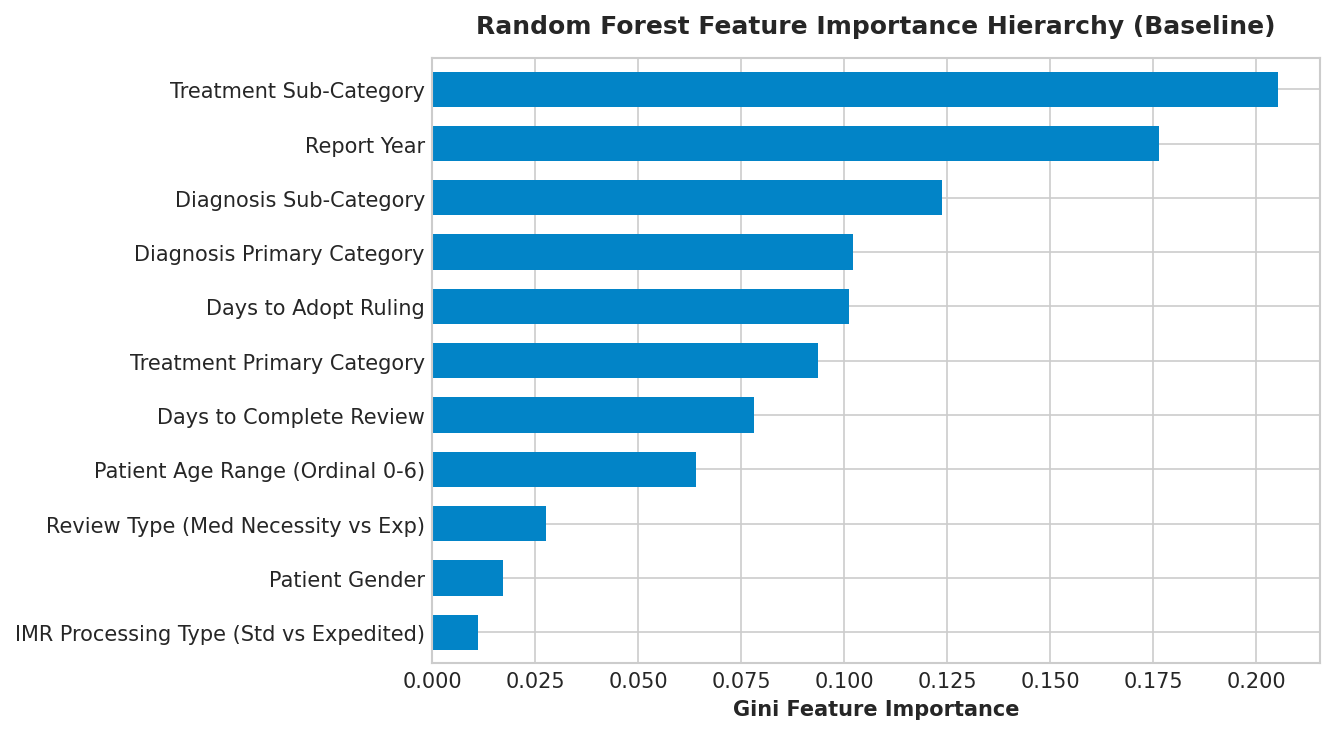

In [45]:
# Figure 7.3: Random Forest Gini Feature Importance
rf_model = trained_models['Random Forest']
feature_names_clean = {
    'ReportYear': 'Report Year',
    'AgeRange_Ord': 'Patient Age Range (Ordinal 0-6)',
    'DaysToReview': 'Days to Complete Review',
    'DaysToAdopt': 'Days to Adopt Ruling',
    'PatientGender_Enc': 'Patient Gender',
    'Type_Enc': 'Review Type (Med Necessity vs Exp)',
    'IMRType_Enc': 'IMR Processing Type (Std vs Expedited)',
    'DiagnosisCategory_Enc': 'Diagnosis Primary Category',
    'DiagnosisSubCategory_Enc': 'Diagnosis Sub-Category',
    'TreatmentCategory_Enc': 'Treatment Primary Category',
    'TreatmentSubCategory_Enc': 'Treatment Sub-Category'
}

feat_importances = pd.Series(rf_model.feature_importances_, index=[feature_names_clean.get(c, c) for c in X.columns])
feat_importances = feat_importances.sort_values(ascending=True)

plt.figure(figsize=(9, 5))
feat_importances.plot(kind='barh', color='#0284c7', width=0.65)
plt.xlabel('Gini Feature Importance', fontweight='bold')
plt.title('Random Forest Feature Importance Hierarchy (Baseline)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 8. Artifact Serialization for Sprint 3 & Explainability (XAI)

In [46]:
# Persist model-ready datasets, encoders, and trained baselines
os.makedirs('data/processed', exist_ok=True)
os.makedirs('models', exist_ok=True)

df_clean.to_csv('imr_processed.csv', index=False)
df_clean.to_csv('data/processed/imr_processed.csv', index=False)

joblib.dump(encoders, 'encoders.pkl')
joblib.dump(encoders, 'models/encoders.pkl')

joblib.dump(scaler, 'scaler.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

joblib.dump(trained_models, 'baseline_models.pkl')
joblib.dump(trained_models, 'models/baseline_models.pkl')

print('All Sprint 2 data, encoder, and model artifacts saved successfully.')

All Sprint 2 data, encoder, and model artifacts saved successfully.


## 9. Sprint 2 Summary & Transition to Sprint 3

### ✅ Sprint 2 Milestone Achievements:
- Cleaned and retained 41,332 cases (96.69%) with zero synthetic imputation distortion.
- Mitigated retrospective narrative leakage by sequestering reviewer `Findings` text.
- Achieved **0.747 ROC-AUC** and **72.52% Precision** on overturned claim denials via Random Forest.
- Hist Gradient Boosting achieved a strong harmonic balance with **0.683 F1-Score** and **68.07% Accuracy**.

### 🔜 Sprint 3 Scope (24 Nov – 07 Dec 2026):
- 5-fold cross-validated hyperparameter optimization (GridSearchCV) across Random Forest, LightGBM, and CatBoost.
- Frequency encoding for high-cardinality clinical categories.
- Champion model architecture selection (`best_model.pkl`) in preparation for SHAP (TreeExplainer) global and local interpretability in Sprints 4 & 5.